# Fase 1: Tokenización y embeddings

## 1. Tokenizar los documentos del corpus

### 1.1. Cargar tokenizador

In [21]:
import os
from dotenv import load_dotenv
from transformers import AutoTokenizer

MODEL = "meta-llama/Llama-3.1-8B-Instruct"

load_dotenv()
ACCESS_TOKEN = os.getenv("HF_TOKEN")

tok_llama = AutoTokenizer.from_pretrained(MODEL, token=ACCESS_TOKEN)

### 1.2. Tokenizar documentos

In [2]:
from pathlib import Path


def tokenizar_documento(doc, tok):
    ruta = Path(doc)
    archivo = ruta.name
    categoria = ruta.parent.name

    # Calcular numero de palabras en el documento
    with open(doc, "r", encoding="utf-8") as f:
        texto = f.read()
        num_palabras = len(texto.split())

    # Tokenizar el documento
    print(f"Tokenizando {archivo}...")
    tokens = tok.tokenize(texto)
    num_tokens = len(tokens)

    # Ratio tokens/palabras
    ratio = num_tokens / num_palabras if num_palabras > 0 else 0

    return {
        "archivo": archivo,
        "categoria": categoria,
        "tokens": tokens,
        "num_palabras": num_palabras,
        "num_tokens": num_tokens,
        "ratio": ratio,
    }


In [3]:
import os

folder_path = "./corpus/"
tokens_docs = []

# Recorrer los documentos de la carpeta y tokenizarlos
for root, _, files in os.walk(folder_path):
    for file in files:
        if file.endswith(".md"):
            doc_path = os.path.join(root, file)
            tokens_docs.append(tokenizar_documento(doc_path, tok_llama))

Tokenizando cookies_guide.md...
Tokenizando gdpr_explained.md...
Tokenizando google_privacy.md...
Tokenizando spotify_privacy.md...
Tokenizando google_terms.md...
Tokenizando spotify_terms.md...


### 1.3. Estadísticas del corpus

In [4]:
# Estadísticas de Tokenización por Documento

from prettytable import PrettyTable
table = PrettyTable()

headers = ["Archivo", "Categoria", "Nº Palabras", "Nº Tokens", "Ratio"]

for doc in tokens_docs:
    table.add_row([doc['archivo'], doc['categoria'], doc['num_palabras'], doc['num_tokens'], f"{doc['ratio']:.2f}"])

table.title = "Estadísticas de Tokenización por Documento"
table.field_names = headers
print(table)

# Ratio es mayor en textos en español

+-------------------------------------------------------------------------+
|                Estadísticas de Tokenización por Documento               |
+--------------------+------------------+-------------+-----------+-------+
|      Archivo       |    Categoria     | Nº Palabras | Nº Tokens | Ratio |
+--------------------+------------------+-------------+-----------+-------+
|  cookies_guide.md  |      guides      |     2148    |    2613   |  1.22 |
| gdpr_explained.md  |      guides      |     2268    |    2775   |  1.22 |
| google_privacy.md  | privacy_policies |     5782    |    6928   |  1.20 |
| spotify_privacy.md | privacy_policies |     5572    |    8175   |  1.47 |
|  google_terms.md   |      terms       |     5575    |    6832   |  1.23 |
|  spotify_terms.md  |      terms       |     6714    |   10753   |  1.60 |
+--------------------+------------------+-------------+-----------+-------+


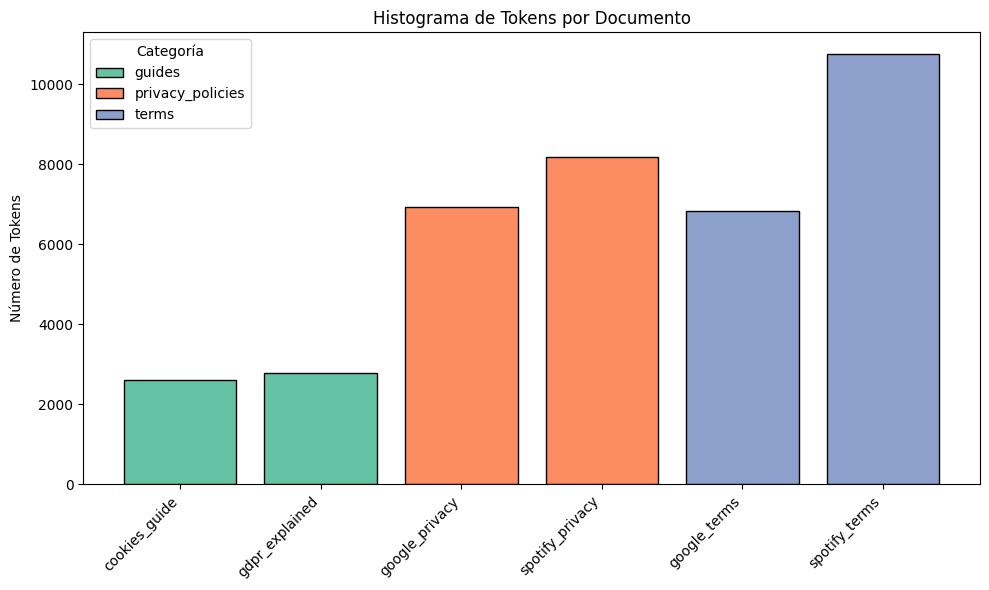

In [ ]:
# Histograma de Tokens por Documento
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


docs = [doc["archivo"].replace(".md", "") for doc in tokens_docs]
num_tokens_list = [doc["num_tokens"] for doc in tokens_docs]
categorias = [doc["categoria"] for doc in tokens_docs]

# Asignar un color distinto a cada categoria
categorias_unicas = sorted(set(categorias))
palette = plt.cm.Set1.colors
color_map = {cat: palette[i % len(palette)] for i, cat in enumerate(categorias_unicas)}
bar_colors = [color_map[cat] for cat in categorias]

plt.figure(figsize=(10, 6))
plt.bar(docs, num_tokens_list, edgecolor="black", color=bar_colors)
plt.title("Histograma de Tokens por Documento")
plt.ylabel("Número de Tokens")
plt.xticks(rotation=45, ha="right")

legend_handles = [Patch(facecolor=color_map[cat], edgecolor="black", label=cat) for cat in categorias_unicas]
plt.legend(handles=legend_handles, title="Categoría")

plt.tight_layout()
plt.show()


In [6]:
# Estadísticas Globales del Corpus
total_docs = len(tokens_docs)
total_palabras = sum(doc['num_palabras'] for doc in tokens_docs)
total_tokens = sum(doc['num_tokens'] for doc in tokens_docs)
ratio_global = total_tokens / total_palabras if total_palabras > 0 else 0
media_tokens = total_tokens / total_docs if total_docs > 0 else 0

table = PrettyTable()
table.title = "Estadísticas Globales del Corpus"
table.field_names = ["Métrica", "Valor"]
table.add_row(["Total Documentos", total_docs])
table.add_row(["Total Palabras", total_palabras])
table.add_row(["Total Tokens", total_tokens])
table.add_row(["Ratio (Tokens/Palabra)", f"{ratio_global:.2f}"])
table.add_row(["Media Tokens por Documento", f"{media_tokens:.2f}"])
print(table)

+--------------------------------------+
|   Estadísticas Globales del Corpus   |
+----------------------------+---------+
|          Métrica           |  Valor  |
+----------------------------+---------+
|      Total Documentos      |    6    |
|       Total Palabras       |  28059  |
|        Total Tokens        |  38076  |
|   Ratio (Tokens/Palabra)   |   1.36  |
| Media Tokens por Documento | 6346.00 |
+----------------------------+---------+


In [20]:
vocabulario_docs = {}

SIGNOS = set(".,;:!?()[]|{}\"'-")
STOPWORDS = set(["el", "la", "los", "las", "un", "una", "unos", "unas", "y", "o", "de", "a", "en", "que", "con", "an", "the", "and", "or", "of", "to", "in", "is", "that", "it", "for", "on", "with", ])
TOKENS_ESPECIALES = set(["Ċ", "Ġ", ".ĊĊ", "ĊĊ", ""])
EXCLUIR = SIGNOS.union(STOPWORDS).union(TOKENS_ESPECIALES)

# Por documento
for doc in tokens_docs:
    vocabulario_doc = {}
    for token in doc["tokens"]:
        # Eliminar el token especial Ġ
        token = token.replace("Ġ", "")
        # Eliminar tokens que están en la lista de exclusión
        if token in EXCLUIR:
            continue
        # Contar la frecuencia del token en el documento
        if token in vocabulario_doc:
            vocabulario_doc[token] += 1
        else:
            vocabulario_doc[token] = 1
    vocabulario_docs[doc["archivo"]] = vocabulario_doc

# Global
vocabulario_global = {}
for vocab_doc in vocabulario_docs.values():
    for token, frecuencia in vocab_doc.items():
        if token in vocabulario_global:
            vocabulario_global[token] += frecuencia
        else:
            vocabulario_global[token] = frecuencia

# Top 10 tokens por documento
for i, (archivo, vocab_doc) in enumerate(vocabulario_docs.items()):
    top_tokens = sorted(vocab_doc.items(), key=lambda x: x[1], reverse=True)[:10]
    print(f"Top 10 Tokens {archivo}")
    for token, frecuencia in top_tokens:
        print(f"{token}: {frecuencia}")
    print()

# Top 20 tokens globales
top_tokens_global = sorted(vocabulario_global.items(), key=lambda x: x[1], reverse=True)[:20]
print("Top 20 Tokens Globales")
for token, frecuencia in top_tokens_global:
    print(f"{token}: {frecuencia}")

Top 10 Tokens cookies_guide.md
cookies: 83
you: 52
your: 47
are: 45
Cookies: 25
web: 23
-party: 22
website: 21
can: 19
as: 18

Top 10 Tokens gdpr_explained.md
data: 76
you: 51
GDPR: 38
The: 34
are: 22
right: 19
You: 19
âĢĻs: 17
this: 17
your: 17

Top 10 Tokens google_privacy.md
your: 230
you: 217
information: 150
Google: 147
services: 106
use: 93
our: 90
we: 88
We: 73
like: 51

Top 10 Tokens spotify_privacy.md
datos: 117
Spotify: 109
Datos: 106
para: 78
tu: 74
ales: 71
os: 71
es: 67
as: 64
tus: 59

Top 10 Tokens google_terms.md
you: 160
services: 103
Google: 87
our: 76
content: 75
we: 73
your: 73
terms: 61
these: 52
as: 51

Top 10 Tokens spotify_terms.md
Spotify: 176
os: 148
su: 91
min: 84
T: 82
es: 80
Serv: 76
icio: 76
Ã©r: 67
DE: 67

Top 20 Tokens Globales
you: 480
your: 367
Spotify: 285
Google: 239
os: 219
services: 213
as: 210
information: 173
we: 171
our: 166
es: 148
data: 138
use: 136
datos: 119
se: 115
para: 114
Serv: 114
icio: 113
content: 109
an: 108


## 2. Embeddings

### 2.1. Selección de Fragmentos de cada Documento 

In [1]:
FRAGMENTOS = {
    "guides": {
        "cookies_guide": [
            "Cookies are text files with small pieces of data — like a username and password — that are used to identify your computer as you use a network.",
            "Cookies let websites remember you, your logins, shopping carts and more, enabling a more personal and convenient browsing experience.",
            "Data stored in a cookie is created by the server upon your connection and labeled with a unique ID associated with your device.",
            "Due to international laws, such as the EU’s General Data Protection Regulation (GDPR), many websites are now required to ask for permission to use certain cookies with your browser and provide you with information on how their cookies will be used if you accept.",
            "Third-party cookies can track users across multiple websites, whereas first-party cookies are limited to the site that created them."
        ],
        "gpdr_explained": [
            "The General Data Protection Regulation (GDPR) is the toughest privacy and security law in the world, imposing obligations on organizations that process data of EU residents regardless of their location.",
            "Personal data is any information that relates to an individual who can be directly or indirectly identified, including names, emails, location data, and even web cookies.",
            "If you process personal data, you must adhere to principles such as lawfulness, transparency, data minimization, accuracy, storage limitation, and accountability.",
            "Organizations must implement appropriate technical and organizational measures to ensure data security, and report data breaches within 72 hours.",
            "Consent under GDPR must be freely given, specific, informed, and unambiguous, and users must be able to withdraw it at any time."
        ]
    },
    "privacy_policies": {
        "google_privacy": [
            "We collect information to provide better services to all our users, from basic preferences like language to more complex data such as ads you may find useful or content you might like.",
            "When you’re signed in, we collect and store information with your Google Account, treating it as personal information.",
            "We collect information about your activity in our services, including searches, videos watched, interactions with ads, and browsing history.",
            "We use the information we collect to provide, maintain, improve, and develop services, as well as to personalize content and ads.",
            "You can control your privacy through settings that allow you to manage, review, export, and delete your personal information."
        ],
        "spotify_privacy": [
            "Spotify recopila y trata datos personales para proporcionar y personalizar su servicio de streaming, incluyendo el uso en distintos dispositivos y la conexión con aplicaciones externas.",
            "Los usuarios tienen derechos sobre sus datos personales, como acceso, rectificación, supresión, oposición y portabilidad, en línea con regulaciones como el RGPD.",
            "Spotify recopila datos de uso como historial de reproducción, búsquedas, listas creadas e interacciones, así como datos técnicos como dirección IP y tipo de dispositivo.",
            "Los datos personales se utilizan para ofrecer el servicio, mejorar funcionalidades, desarrollar nuevas tecnologías y personalizar contenido y publicidad.",
            "Spotify conserva los datos personales solo durante el tiempo necesario para prestar el servicio, cumplir obligaciones legales y mejorar la experiencia del usuario."
        ]
    },
    "terms": {
        "google_terms": [
            "These Terms of Service define the relationship between you and Google, including what you can expect from the services and what Google expects from you as a user.",
            "To use Google services, you must accept these terms, which outline rules, rights, and responsibilities related to accessing and using the services.",
            "Google continuously develops and improves its services, including using artificial intelligence and machine learning to enhance functionality and security.",
            "Users must follow rules such as respecting others, complying with laws, and not abusing services through activities like hacking, fraud, or misuse of content.",
            "Users retain ownership of their content, but grant Google a license to use, host, modify, and distribute it for the purpose of operating and improving services."
        ],
        "spotify_terms": [
            "El uso del Servicio de Spotify implica la aceptación de los Términos, que regulan el acceso a contenidos como música, podcasts y otros materiales.",
            "Spotify ofrece servicios gratuitos y de pago, que pueden modificarse, suspenderse o interrumpirse en función de cambios técnicos, legales o comerciales.",
            "El usuario es responsable de su cuenta y debe mantener la confidencialidad de sus credenciales, siendo responsable de cualquier uso asociado.",
            "El contenido del servicio está protegido por derechos de propiedad intelectual, y el usuario recibe una licencia limitada para uso personal y no comercial.",
            "Spotify puede rescindir el acceso al servicio si el usuario incumple los términos, la ley aplicable o si su conducta causa daño a terceros o a la plataforma."
        ]
    }
}

### 2.2. Generar Embeddings

In [37]:
from sentence_transformers import SentenceTransformer

# Cargar modelo de embeddings de frases
print("Cargando modelo de embeddings...")
model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2")

# Construir lista de fragmentos con metadatos
fragmentos = []
for categoria, archivos in FRAGMENTOS.items():
    for archivo, textos in archivos.items():
        for i, texto in enumerate(textos):
            fragmentos.append({
                "id": f"{archivo}_{i}",
                "categoria": categoria,
                "archivo": archivo,
                "texto": texto,
            })

# Calcular embeddings en batch
textos = [f["texto"] for f in fragmentos]
print("Calculando embeddings para los fragmentos...")
embeddings = model.encode(
    textos, 
    normalize_embeddings=True, 
    show_progress_bar=True
)

# Añadir embeddings a los fragmentos
for i, fragmento in enumerate(fragmentos):
    fragmento["embedding"] = embeddings[i]

Cargando modelo de embeddings...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7994.81it/s]
XLMRobertaModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Calculando embeddings para los fragmentos...


Batches: 100%|██████████| 1/1 [00:00<00:00,  1.09it/s]


### 2.3. Visualización de Embeddings

In [ ]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def obtener_empresa(nombre_archivo):
    if nombre_archivo.startswith("google_"):
        return "Google"
    if nombre_archivo.startswith("spotify_"):
        return "Spotify"
    return "Otros"

def visualizar_embeddings(vectores_2d, fragmentos, titulo):
    # Color por categoria (guides, privacy_policies, terms)
    categorias = [f["categoria"] for f in fragmentos]
    categorias_unicas = sorted(set(categorias))
    palette = plt.cm.Set1.colors
    color_map = {cat: palette[i % len(palette)] for i, cat in enumerate(categorias_unicas)}

    # Simbolo por empresa/documento
    empresas = [obtener_empresa(f["archivo"]) for f in fragmentos]
    marker_map = {
        "Google": "s",   # cuadrado
        "Spotify": "^",  # triangulo
        "Otros": "o",    # circulo
    }

    plt.figure(figsize=(10, 6))
    plt.title(titulo)

    # Dibujar punto a punto para combinar color (categoria) y marcador (empresa)
    for i, fragmento in enumerate(fragmentos):
        categoria = fragmento["categoria"]
        empresa = empresas[i]
        plt.scatter(vectores_2d[i, 0], vectores_2d[i, 1], c=[color_map[categoria]], marker=marker_map.get(empresa, "o"), s=100)
        plt.annotate(fragmento["id"], (vectores_2d[i, 0], vectores_2d[i, 1]), fontsize=8)

    # Leyenda de colores por categoria
    legend_categorias = [Patch(facecolor=color_map[cat], label=cat) for cat in categorias_unicas]
    legend1 = plt.legend(handles=legend_categorias, title="Categoría", loc="upper left")

    # Leyenda de marcadores por empresa
    legend_empresas = [
        Line2D([0], [0], marker=marker, color="w", markerfacecolor="gray", markersize=9, label=empresa)
        for empresa, marker in marker_map.items()
    ]
    legend2 = plt.legend(handles=legend_empresas, title="Documento", loc="upper right")
    plt.gca().add_artist(legend1)

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

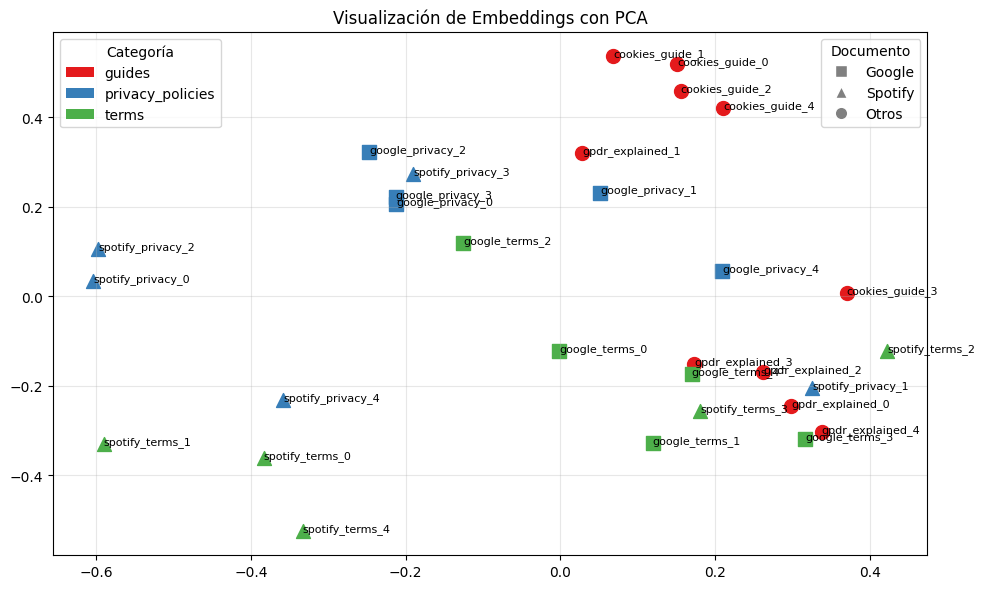

In [32]:
# Visualización con PCA
pca = PCA(n_components=2)
vectores_2d_pca = pca.fit_transform(embeddings)
visualizar_embeddings(vectores_2d_pca, fragmentos, "Visualización de Embeddings con PCA")

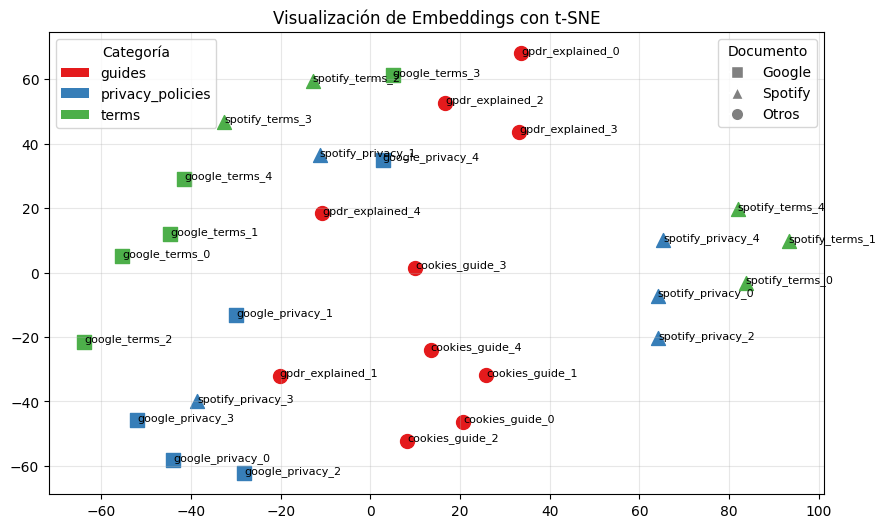

In [45]:
# Visualización con t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
vectores_2d_tsne = tsne.fit_transform(embeddings)
visualizar_embeddings(vectores_2d_tsne, fragmentos, "Visualización de Embeddings con t-SNE")